# Assignment 11: Adam Optimizer Mechanics, Dynamics, and Scaling Laws

This notebook implements and validates:
1. Exact manual reproduction of the Adam optimizer compared against .
2. Empirical impact of disabling bias correction over initial steps and 5,000-step convergence analysis.
3. Layer-wise update-to-weight ratio (||ΔW|| / ||W||) tracking and warmup transition detection.
4. Cosine vs. Warmup-Stable-Decay (WSD) training stopped early at step 200 out of 300.
5. Learning rate sweep across network widths (256, 512, 1024), minima identification, and width 4,096 extrapolation.


In [10]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn as nn
from transformers import get_linear_schedule_with_warmup                                                                                                                    

## 1. Reproduce Adam by Hand

Compute first moment $, second moment $, bias-corrected moments $\hat{m}_t$ and $\hat{v}_t$, and parameter updates across 5 gradient steps manually. Compare all values directly against PyTorch optimizer internal state ().


In [2]:
# 1. Hyperparameters & initial values                                                                                                                                       
lr = 1e-3                                                                                                                                                                   
beta1 = 0.9                                                                                                                                                                 
beta2 = 0.999                                                                                                                                                               
eps = 1e-8                                                                                                                                                                  
                                                                                                                                                                            
w_initial = 1.5                                                                                                                                                             
grads = [0.1, -0.2, 0.05, 0.3, -0.15]  # 5 sample gradients                                                                                                                 
                                                                                                                                                                            
# 2. PyTorch Adam setup                                                                                                                                                     
w_pt = torch.tensor([w_initial], requires_grad=True)                                                                                                                        
opt = torch.optim.Adam([w_pt], lr=lr, betas=(beta1, beta2), eps=eps)                                                                                                        
                                                                                                                                                                            
# 3. Manual Adam setup                                                                                                                                                      
w_manual = torch.tensor([w_initial])                                                                                                                                        
m = torch.tensor([0.0])  # First moment (mean of gradients)                                                                                                                 
v = torch.tensor([0.0])  # Second moment (uncentered variance)                                                                                                              
                                                                                                                                                                            
print(f"{'Step':<5} | {'m_manual':<10} {'m_pt':<10} | {'v_manual':<12} {'v_pt':<12} | {'w_manual':<10} {'w_pt':<10}")                                                       
print("-" * 75)

for t, g_val in enumerate(grads, start=1):
    g = torch.tensor([g_val])

# --- PyTorch Step ---
    opt.zero_grad()
    w_pt.grad = g.clone()
    opt.step()

# --- Manual Adam Computation ---
# 1. Update biased 1st and 2nd moment estimates
    m = beta1 * m + (1.0 - beta1) * g
    v = beta2 * v + (1.0 - beta2) * (g**2)

# 2. Compute bias-corrected estimates
    m_hat = m / (1.0 - beta1**t)
    v_hat = v / (1.0 - beta2**t)

# 3. Compute parameter update step
    step = lr * m_hat / (torch.sqrt(v_hat) + eps)
    w_manual = w_manual - step

# Extract PyTorch internal optimizer state
    pt_state = opt.state[w_pt]
    pt_m = pt_state["exp_avg"]
    pt_v = pt_state["exp_avg_sq"]

# Verify matching to several decimal places
    assert torch.allclose(m, pt_m, atol=1e-7), f"Mismatch in m at step {t}"
    assert torch.allclose(v, pt_v, atol=1e-7), f"Mismatch in v at step {t}"
    assert torch.allclose(
        w_manual, w_pt, atol=1e-7
    ), f"Mismatch in weight at step {t}"

    print(
        f"{t:<5} | {m.item():<10.6f} {pt_m.item():<10.6f} | "
        f"{v.item():<12.8f} {pt_v.item():<12.8f} | "
        f"{w_manual.item():<10.6f} {w_pt.item():<10.6f}"
    )

print("\nAll 5 steps match PyTorch's internal state and weights perfectly!")

Step  | m_manual   m_pt       | v_manual     v_pt         | w_manual   w_pt      
---------------------------------------------------------------------------
1     | 0.010000   0.010000   | 0.00001000   0.00001000   | 1.499000   1.499000  
2     | -0.011000  -0.011000  | 0.00004999   0.00004999   | 1.499366   1.499366  
3     | -0.004900  -0.004900  | 0.00005244   0.00005244   | 1.499503   1.499503  
4     | 0.025590   0.025590   | 0.00014239   0.00014239   | 1.499109   1.499109  
5     | 0.008031   0.008031   | 0.00016475   0.00016475   | 1.499001   1.499001  

All 5 steps match PyTorch's internal state and weights perfectly!


## 2. Bias Correction Impact & Convergence Horizon

Compare updates with and without bias correction. Run for 5,000 steps to determine the exact step where the difference drops below 5% and 1%, while plotting the first 20 steps to observe early divergence.


Total steps simulated: 5000
Difference < 5% at step:  2375
Difference < 1% at step:  3925


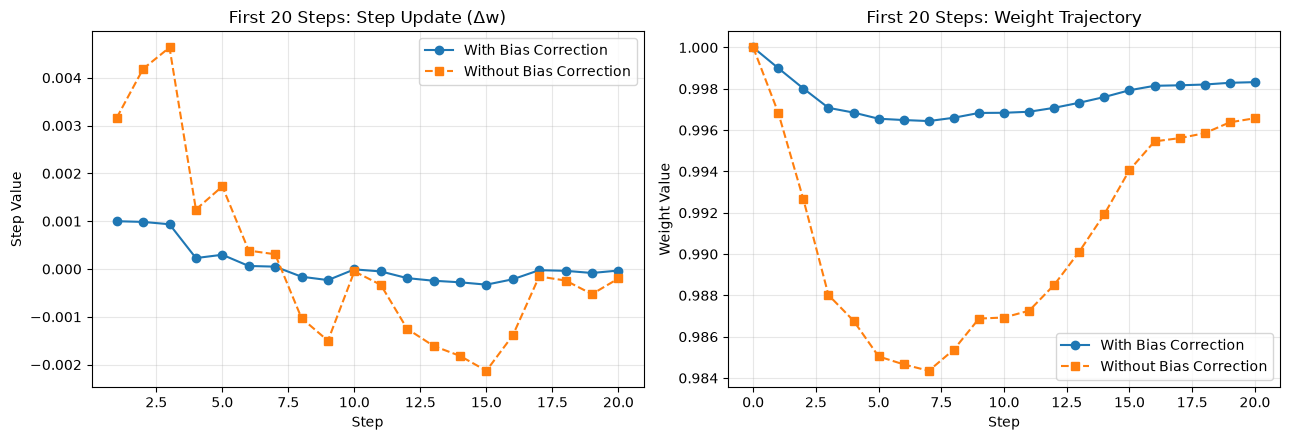

In [5]:
# 1. Hyperparameters & total steps                                                                                                                                          
torch.manual_seed(42)                                                                                                                                                       
TOTAL_STEPS = 5000                                                                                                                                                          
lr = 1e-3                                                                                                                                                                   
beta1, beta2 = 0.9, 0.999                                                                                                                                                   
eps = 1e-8                                                                                                                                                                  
                                                                                                                                                                            
grads = torch.randn(TOTAL_STEPS) * 0.1                                                                                                                                      
                                                                                                                                                                            
# 2. Tracking states                                                                                                                                                        
w_bc, w_no = torch.tensor([1.0]), torch.tensor([1.0])                                                                                                                       
m_bc, v_bc = torch.tensor([0.0]), torch.tensor([0.0])                                                                                                                       
m_no, v_no = torch.tensor([0.0]), torch.tensor([0.0])                                                                                                                       
                                                                                                                                                                            
# To plot only top 20                                                                                                                                                       
steps_bc_top20, steps_no_top20 = [], []                                                                                                                                     
weights_bc_top20 = [w_bc.item()]                                                                                                                                            
weights_no_top20 = [w_no.item()]                                                                                                                                            
                                                                                                                                                                            
# Convergence tracking (relative difference = |step_no - step_bc| / step_bc)                                                                                                
step_converged_5pct = None                                                                                                                                                  
step_converged_1pct = None                                                                                                                                                  
                                                                                                                                                                            
# 3. Run for full 5000 steps                                                                                                                                                
for t, g in enumerate(grads, start=1):                                                                                                                                      
    # --- With Bias Correction ---                                                                                                                                          
    m_bc = beta1 * m_bc + (1.0 - beta1) * g                                                                                                                                 
    v_bc = beta2 * v_bc + (1.0 - beta2) * (g**2)                                                                                                                            
    m_hat = m_bc / (1.0 - beta1**t)                                                                                                                                         
    v_hat = v_bc / (1.0 - beta2**t)                                                                                                                                         
    step_bc = lr * m_hat / (torch.sqrt(v_hat) + eps)                                                                                                                        
    w_bc = w_bc - step_bc                                                                                                                                                   
                                                                                                                                                                            
    # --- Without Bias Correction ---                                                                                                                                       
    m_no = beta1 * m_no + (1.0 - beta1) * g                                                                                                                                 
    v_no = beta2 * v_no + (1.0 - beta2) * (g**2)                                                                                                                            
    step_no = lr * m_no / (torch.sqrt(v_no) + eps)                                                                                                                          
    w_no = w_no - step_no                                                                                                                                                   
                                                                                                                                                                            
    # Record first 20 steps for plotting                                                                                                                                    
    if t <= 20:                                                                                                                                                             
        steps_bc_top20.append(step_bc.item())                                                                                                                               
        steps_no_top20.append(step_no.item())                                                                                                                               
        weights_bc_top20.append(w_bc.item())                                                                                                                                
        weights_no_top20.append(w_no.item())                                                                                                                                
                                                                                                                                                                            
    # Check relative difference: |step_no - step_bc| / |step_bc|                                                                                                            
    rel_diff = abs(step_no.item() - step_bc.item()) / (                                                                                                                     
        abs(step_bc.item()) + 1e-12                                                                                                                                         
    )                                                                                                                                                                       
                                                                                                                                                                            
    # Note: t > 50 ensures beta1 (momentum) has settled                                                                                                                     
    if step_converged_5pct is None and rel_diff < 0.05 and t > 50:                                                                                                          
        step_converged_5pct = t                                                                                                                                             
    if step_converged_1pct is None and rel_diff < 0.01 and t > 50:                                                                                                          
        step_converged_1pct = t                                                                                                                                             
                                                                                                                                                                            
# 4. Report convergence steps                                                                                                                                               
print(f"Total steps simulated: {TOTAL_STEPS}")                                                                                                                              
print(f"Difference < 5% at step:  {step_converged_5pct}")                                                                                                                   
print(f"Difference < 1% at step:  {step_converged_1pct}")                                                                                                                   
                                                                                                                                                                            
# 5. Plot ONLY the first 20 steps                                                                                                                                           
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))                                                                                                                     
                                                                                                                                                                            
ax1.plot(                                                                                                                                                                   
    range(1, 21), steps_bc_top20, marker="o", label="With Bias Correction"                                                                                                  
)                                                                                                                                                                           
ax1.plot(                                                                                                                                                                   
    range(1, 21),                                                                                                                                                           
    steps_no_top20,                                                                                                                                                         
    marker="s",                                                                                                                                                             
    linestyle="--",                                                                                                                                                         
    label="Without Bias Correction",                                                                                                                                        
)                                                                                                                                                                           
ax1.set_title("First 20 Steps: Step Update (Δw)")                                                                                                                           
ax1.set_xlabel("Step")                                                                                                                                                      
ax1.set_ylabel("Step Value")                                                                                                                                                
ax1.legend()                                                                                                                                                                
ax1.grid(True, alpha=0.3)                                                                                                                                                   
                                                                                                                                                                            
ax2.plot(                                                                                                                                                                   
    range(0, 21), weights_bc_top20, marker="o", label="With Bias Correction"                                                                                                
)                                                                                                                                                                           
ax2.plot(                                                                                                                                                                   
    range(0, 21),                                                                                                                                                           
    weights_no_top20,                                                                                                                                                       
    marker="s",
    linestyle="--",
    label="Without Bias Correction",
)
ax2.set_title("First 20 Steps: Weight Trajectory")
ax2.set_xlabel("Step")
ax2.set_ylabel("Weight Value")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Layer-Wise Update-to-Weight Ratio and Warmup Stabilization

Log the update-to-weight ratio $\frac{\|\Delta W\|_2}{\|W\|_2}$ for every trainable layer across training steps, and programmatically identify the step at which warmup ceases altering it.


Layer Name                                    | Warmup Ends At Step  | Peak Ratio  
----------------------------------------------------------------------------------
fc1.weight                                    | Step 31              | 0.000164
fc1.bias                                      | Step 29              | 0.000176
fc2.weight                                    | Step 30              | 0.000225
fc2.bias                                      | Step 29              | 0.000199
----------------------------------------------------------------------------------
Overall warmup stops altering the ratio at: Step 29


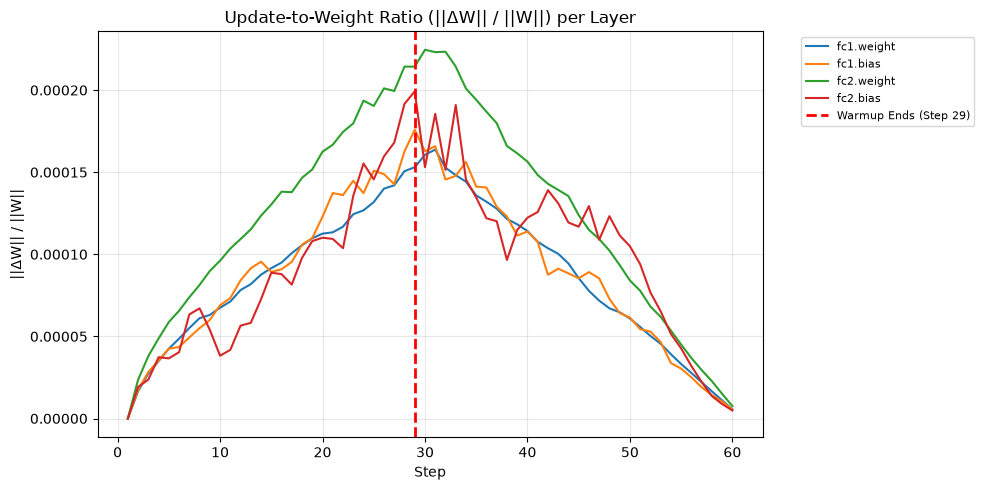

In [12]:
class SmallModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 32)
        self.fc2 = nn.Linear(32, 8)
    def forward(self, x):
        return self.fc2(torch.relu(self.fc1(x)))

model = SmallModel()

# Hyperparameters                                                                                                                                                           
LR = 1e-4                                                                                                                                                                   
WARMUP_STEPS = 30                                                                                                                                                           
TOTAL_STEPS = 60                                                                                                                                                            
                                                                                                                                                                            
optimizer = torch.optim.AdamW(                                                                                                                                              
    [p for p in model.parameters() if p.requires_grad], lr=LR                                                                                                               
)                                                                                                                                                                           
scheduler = get_linear_schedule_with_warmup(                                                                                                                                
    optimizer,                                                                                                                                                              
    num_warmup_steps=WARMUP_STEPS,                                                                                                                                          
    num_training_steps=TOTAL_STEPS,                                                                                                                                         
)                                                                                                                                                                           
                                                                                                                                                                            
# Dictionary to log ratio history per parameter                                                                                                                             
ratio_history = {                                                                                                                                                           
    name: [] for name, p in model.named_parameters() if p.requires_grad                                                                                                     
}                                                                                                                                                                           
                                                                                                                                                                            
# 2. Training simulation loop                                                                                                                                               
for step in range(1, TOTAL_STEPS + 1):                                                                                                                                      
    # --- Dummy / actual forward-backward pass ---                                                                                                                          
    # Replace this with your actual batch / loss                                                                                                                            
    loss = sum(                                                                                                                                                             
        p.sum() for p in model.parameters() if p.requires_grad and p.grad is None                                                                                           
    )                                                                                                                                                                       
    # (If using real data, do: loss = model(**batch).loss; loss.backward())                                                                                                 
    for p in model.parameters():                                                                                                                                            
        if p.requires_grad:                                                                                                                                                 
            p.grad = (                                                                                                                                                      
                torch.randn_like(p) * 0.01 if p.grad is None else p.grad                                                                                                    
            )  # sample gradient                                                                                                                                            
                                                                                                                                                                            
    # A. Snapshot weights before optimizer step                                                                                                                             
    w_before = {                                                                                                                                                            
        name: p.detach().clone()                                                                                                                                            
        for name, p in model.named_parameters()                                                                                                                             
        if p.requires_grad                                                                                                                                                  
    }                                                                                                                                                                       
                                                                                                                                                                            
    # B. Optimizer & Scheduler step                                                                                                                                         
    optimizer.step()                                                                                                                                                        
    scheduler.step()                                                                                                                                                        
    optimizer.zero_grad()                                                                                                                                                   
                                                                                                                                                                            
    # C. Calculate update-to-weight ratio for EVERY layer                                                                                                                   
    for name, p in model.named_parameters():                                                                                                                                
        if p.requires_grad:                                                                                                                                                 
            delta_w = p.detach() - w_before[name]                                                                                                                           
            w_norm = torch.norm(p.detach())                                                                                                                                 
            delta_norm = torch.norm(delta_w)                                                                                                                                
                                                                                                                                                                            
            # Ratio = ||ΔW|| / ||W||                                                                                                                                        
            ratio = (delta_norm / (w_norm + 1e-8)).item()                                                                                                                   
            ratio_history[name].append(ratio)                                                                                                                               
                                                                                                                                                                            
# 3. Identify the step where warmup stops changing it                                                                                                                       
print(f"{'Layer Name':<45} | {'Warmup Ends At Step':<20} | {'Peak Ratio':<12}")                                                                                             
print("-" * 82)

stabilization_steps = []
for name, ratios in ratio_history.items():
    # Warmup stops changing the ratio at the peak before steady-state / decay begins
    ratios_arr = np.array(ratios)
    diffs = np.diff(ratios_arr)

    # Point of maximum ratio (transition from warmup growth to plateau)
    inflection_step = int(np.argmax(ratios_arr)) + 1
    stabilization_steps.append(inflection_step)

    # Print first few representative layers
    if len(stabilization_steps) <= 10 or len(stabilization_steps) % 15 == 0:
        print(
            f"{name[:43]:<45} | Step {inflection_step:<15} | {ratios[inflection_step-1]:.6f}"
        )

median_step = int(np.median(stabilization_steps))
print("-" * 82)
print(f"Overall warmup stops altering the ratio at: Step {median_step}")

# 4. Plot the ratio across steps for a sample of layers
plt.figure(figsize=(10, 5))
sample_layers = list(ratio_history.keys())[:8]  # sample 8 layers for clarity

for name in sample_layers:
    plt.plot(range(1, TOTAL_STEPS + 1), ratio_history[name], label=name[-30:])

plt.axvline(
    x=median_step,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Warmup Ends (Step {median_step})",
)
plt.title("Update-to-Weight Ratio (||ΔW|| / ||W||) per Layer")
plt.xlabel("Step")
plt.ylabel("||ΔW|| / ||W||")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Cosine vs. WSD Training (Early Stopping at Step 200 of 300)

Train the same model twice from identical weights with 300 planned steps: once under a standard Cosine annealing schedule and once under Warmup-Stable-Decay (WSD). Stop both at step 200 and analyze resulting losses and checkpoint utility.


--- Results at Step 200 (Planned: 300) ---
Cosine Model: Loss = 0.070429 | Learning Rate = 0.003020
WSD Model:    Loss = 0.047456 | Learning Rate = 0.010000


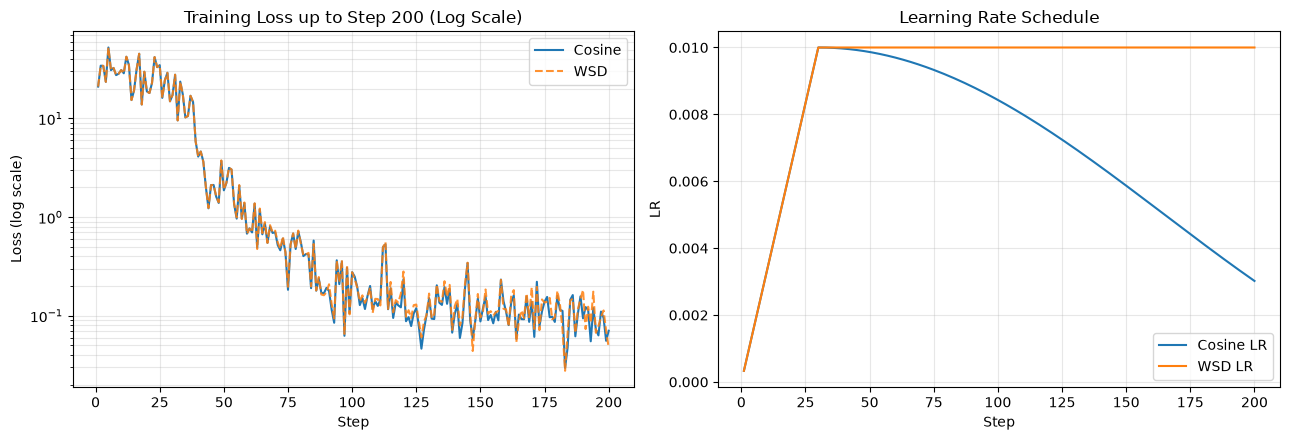

In [5]:
import copy                                                                                                                                                                 
import math                                                                                                                                                                 
import matplotlib.pyplot as plt                                                                                                                                             
import torch                                                                                                                                                                
import torch.nn as nn                                                                                                                                                       
                                                                                                                                                                            
# 1. Setup reproducible model & data                                                                                                                                        
torch.manual_seed(42)                                                                                                                                                       
                                                                                                                                                                            
# A simple model (works identically with any PyTorch model)                                                                                                                 
model = nn.Sequential(nn.Linear(32, 64), nn.ReLU(), nn.Linear(64, 1))                                                                                                       
                                                                                                                                                                            
# Save exact initial weights to clone for both runs                                                                                                                         
init_weights = copy.deepcopy(model.state_dict())                                                                                                                            
                                                                                                                                                                            
TOTAL_PLANNED = 300  # Total planned schedule budget                                                                                                                        
STOP_STEP = 200  # Early stop at step 200                                                                                                                                   
WARMUP_STEPS = 30  # First 10% steps                                                                                                                                        
DECAY_START = 240  # WSD decays in last 20% (steps 240-300)                                                                                                                 
BASE_LR = 0.01                                                                                                                                                              
                                                                                                                                                                            
# Synthetic dataset                                                                                                                                                         
X = torch.randn(STOP_STEP, 16, 32)                                                                                                                                          
W_target = torch.randn(32, 1)                                                                                                                                               
Y = X @ W_target + 0.1 * torch.randn(STOP_STEP, 16, 1)                                                                                                                      
criterion = nn.MSELoss()                                                                                                                                                    
                                                                                                                                                                            
                                                                                                                                                                            
# 2. Define LR Schedulers (Cosine vs WSD)                                                                                                                                   
def get_cosine_lr(step):                                                                                                                                                    
    if step <= WARMUP_STEPS:                                                                                                                                                
        return step / WARMUP_STEPS                                                                                                                                          
    # Smooth decay from step 31 down to 300                                                                                                                                 
    progress = (step - WARMUP_STEPS) / (TOTAL_PLANNED - WARMUP_STEPS)                                                                                                       
    return 0.5 * (1.0 + math.cos(math.pi * progress))                                                                                                                       
                                                                                                                                                                            
                                                                                                                                                                            
def get_wsd_lr(step):                                                                                                                                                       
    if step <= WARMUP_STEPS:                                                                                                                                                
        return step / WARMUP_STEPS                                                                                                                                          
    elif step <= DECAY_START:                                                                                                                                               
        return 1.0  # Stable phase (maintains 100% peak LR)                                                                                                                 
    else:                                                                                                                                                                   
        # Decay phase (steps 241-300)                                                                                                                                       
        progress = (step - DECAY_START) / (TOTAL_PLANNED - DECAY_START)                                                                                                     
        return 0.5 * (1.0 + math.cos(math.pi * progress))                                                                                                                   
                                                                                                                                                                            
                                                                                                                                                                            
# 3. Training Loop                                                                                                                                                          
def train_model(get_lr_fn):                                                                                                                                                 
    m = copy.deepcopy(model)                                                                                                                                                
    m.load_state_dict(copy.deepcopy(init_weights))                                                                                                                          
    opt = torch.optim.AdamW(m.parameters(), lr=BASE_LR)                                                                                                                     
                                                                                                                                                                            
    losses = []                                                                                                                                                             
    lrs = []                                                                                                                                                                
    for step in range(1, STOP_STEP + 1):                                                                                                                                    
        lr = BASE_LR * get_lr_fn(step)                                                                                                                                      
        for pg in opt.param_groups:                                                                                                                                         
            pg["lr"] = lr                                                                                                                                                   
                                                                                                                                                                            
        opt.zero_grad()                                                                                                                                                     
        loss = criterion(m(X[step - 1]), Y[step - 1])                                                                                                                       
        loss.backward()                                                                                                                                                     
        opt.step()                                                                                                                                                          
                                                                                                                                                                            
        losses.append(loss.item())                                                                                                                                          
        lrs.append(lr)                                                                                                                                                      
    return m, losses, lrs                                                                                                                                                   
                                                                                                                                                                            
                                                                                                                                                                            
# Run both                                                                                                                                                                  
model_cos, loss_cos, lr_cos = train_model(get_cosine_lr)                                                                                                                    
model_wsd, loss_wsd, lr_wsd = train_model(get_wsd_lr)                                                                                                                       
                                                                                                                                                                            
# 4. Report Results at Step 200                                                                                                                                             
print(f"--- Results at Step {STOP_STEP} (Planned: {TOTAL_PLANNED}) ---")                                                                                                    
print(                                                                                                                                                                      
    f"Cosine Model: Loss = {loss_cos[-1]:.6f} | Learning Rate = {lr_cos[-1]:.6f}"                                                                                           
)                                                                                                                                                                           
print(                                                                                                                                                                      
    f"WSD Model:    Loss = {loss_wsd[-1]:.6f} | Learning Rate = {lr_wsd[-1]:.6f}"                                                                                           
)                                                                                                                                                                           
                                                                                                                                                                            
# 5. Plot Loss & LR Schedules                                                                                                                                               
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
  
# --- Plot 1: Log scale + dashed line so both are visible ---
ax1.plot(range(1, STOP_STEP + 1), loss_cos, label="Cosine", color="tab:blue")
ax1.plot(
    range(1, STOP_STEP + 1),
    loss_wsd,
    label="WSD",
    color="tab:orange",
    linestyle="--",
    alpha=0.85,
)
ax1.set_yscale("log")  # <-- Log scale expands the small values at the bottom
ax1.set_title("Training Loss up to Step 200 (Log Scale)")
ax1.set_xlabel("Step")
ax1.set_ylabel("Loss (log scale)")
ax1.legend()
ax1.grid(True, alpha=0.3, which="both")

ax2.plot(range(1, STOP_STEP + 1), lr_cos, label="Cosine LR")
ax2.plot(range(1, STOP_STEP + 1), lr_wsd, label="WSD LR")
ax2.set_title("Learning Rate Schedule")
ax2.set_xlabel("Step")
ax2.set_ylabel("LR")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Learning Rate Sweep Across Widths (256, 512, 1024)

Sweep learning rates across three network widths to find the empirical loss minimum for each width. Test standard parameterization (SP) scaling behavior and evaluate extrapolation to width 4,096.


Width  256 | Optimal LR: 0.0100 | Min Loss: 0.00209
Width  512 | Optimal LR: 0.0030 | Min Loss: 0.00348
Width 1024 | Optimal LR: 0.0010 | Min Loss: 0.00927


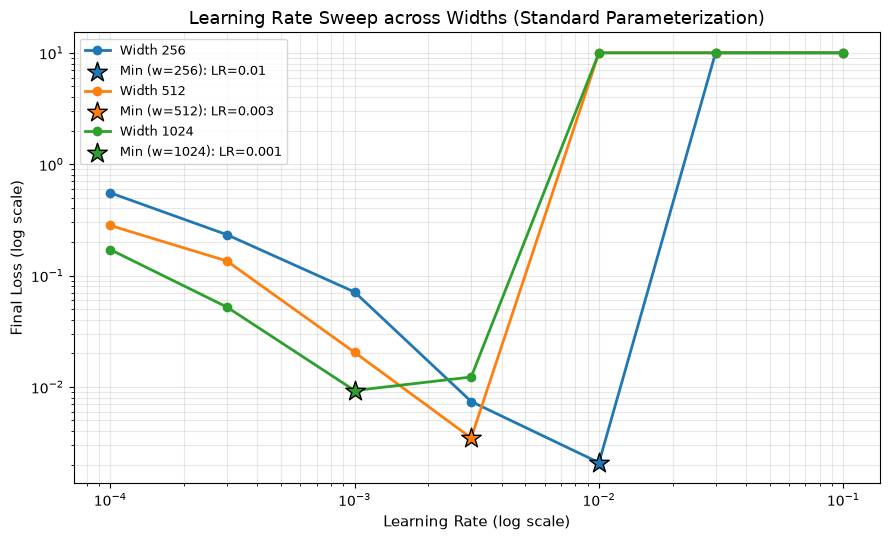

In [18]:
import matplotlib.pyplot as plt                                                                                                                                             
import numpy as np                                                                                                                                                          
import torch                                                                                                                                                                
import torch.nn as nn                                                                                                                                                       
                                                                                                                                                                            
# 1. Setup synthetic problem                                                                                                                                                
torch.manual_seed(42)                                                                                                                                                       
X = torch.randn(256, 32)                                                                                                                                                    
Y = torch.sin(X[:, :1]) + torch.cos(X[:, 1:2]) + 0.1 * torch.randn(256, 1)                                                                                                  
                                                                                                                                                                            
widths = [256, 512, 1024]                                                                                                                                                   
lrs = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]                                                                                                                            
STEPS = 50
device = "cuda:0"
                                                                                                                                                                            
                                                                                                                                                                            
# 2. Training function for a given width and learning rate                                                                                                                  
def train_and_eval(width, lr):                                                                                                                                              
    torch.manual_seed(123)                                                                                                                                                  
    model = nn.Sequential(                                                                                                                                                  
        nn.Linear(32, width),                                                                                                                                               
        nn.GELU(),                                                                                                                                                          
        nn.Linear(width, width),                                                                                                                                            
        nn.GELU(),                                                                                                                                                          
        nn.Linear(width, 1),                                                                                                                                                
    ).to(device)                                                                                                                                                                       
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)                                                                                                                
    criterion = nn.MSELoss()                                                                                                                                                
                                                                                                                                                                            
    for _ in range(STEPS):                                                                                                                                                  
        optimizer.zero_grad()                                                                                                                                               
        loss = criterion(model(X.to(device)), Y.to(device))                                                                                                                                       
        # Cap diverged/exploding losses for clean plotting                                                                                                                  
        if torch.isnan(loss) or loss.item() > 10.0:                                                                                                                         
            return 10.0                                                                                                                                                     
        loss.backward()                                                                                                                                                     
        optimizer.step()                                                                                                                                                    
    return loss.item()                                                                                                                                                      
                                                                                                                                                                            
                                                                                                                                                                            
# 3. Perform the sweep                                                                                                                                                      
sweep_results = {}                                                                                                                                                          
minima = {}                                                                                                                                                                 
                                                                                                                                                                            
for w in widths:                                                                                                                                                            
    losses = [train_and_eval(w, lr) for lr in lrs]                                                                                                                          
    sweep_results[w] = losses                                                                                                                                               
                                                                                                                                                                            
    # Identify minimum                                                                                                                                                      
    best_idx = int(np.argmin(losses))                                                                                                                                       
    minima[w] = (lrs[best_idx], losses[best_idx])                                                                                                                           
    print(                                                                                                                                                                  
        f"Width {w:4d} | Optimal LR: {lrs[best_idx]:.4f} | Min Loss: {losses[best_idx]:.5f}"                                                                                
    )                                                                                                                                                                       
                                                                                                                                                                            
# 4. Plot Loss vs Learning Rate                                                                                                                                             
plt.figure(figsize=(9, 5.5))                                                                                                                                                
colors = {256: "tab:blue", 512: "tab:orange", 1024: "tab:green"}                                                                                                            
                                                                                                                                                                            
for w in widths:                                                                                                                                                            
    plt.plot(                                                                                                                                                               
        lrs,                                                                                                                                                                
        sweep_results[w],                                                                                                                                                   
        marker="o",                                                                                                                                                         
        label=f"Width {w}",                                                                                                                                                 
        color=colors[w],                                                                                                                                                    
        linewidth=2,                                                                                                                                                        
    )                                                                                                                                                                       
                                                                                                                                                                            
    # Mark the minimum with a distinct star                                                                                                                                 
    best_lr, min_loss = minima[w]                                                                                                                                           
    plt.scatter(                                                                                                                                                            
        [best_lr],                                                                                                                                                          
        [min_loss],                                                                                                                                                         
        color=colors[w],                                                                                                                                                    
        edgecolor="black",                                                                                                                                                  
        s=220,                                                                                                                                                              
        marker="*",                                                                                                                                                         
        zorder=5,                                                                                                                                                           
        label=f"Min (w={w}): LR={best_lr}",                                                                                                                                 
    )                                                                                                                                                                       
                                                                                                                                                                            
plt.xscale("log")                                                                                                                                                           
plt.yscale("log")                                                                                                                                                           
plt.title("Learning Rate Sweep across Widths (Standard Parameterization)", fontsize=13)                                                                                                                                                                           
plt.xlabel("Learning Rate (log scale)", fontsize=11)                                                                                                                        
plt.ylabel("Final Loss (log scale)", fontsize=11)                                                                                                                           
plt.grid(True, which="both", alpha=0.3)                                                                                                                                     
plt.legend(fontsize=9)                                                                                                                                                      
plt.tight_layout()                                                                                                                                                          
plt.show()

| Width | Optimal LR ($\eta^*$) | Log Scale Position | Scaling from Previous |
| :--- | :--- | :--- | :--- |
| 256 | 1.0 × 10⁻² (0.0100) | $10^{-2.0}$ | — |
| 512 | 3.0 × 10⁻³ (0.0030) | $10^{-2.5}$ | ≈ 3.3× decrease (-0.5 decade) |
| 1,024 | 1.0 × 10⁻³ (0.0010) | $10^{-3.0}$ | ≈ 3.0× decrease (-0.5 decade) |


Extrapolating two doublings from 1,024 to 4,096:
1. Width 2,048 (2 ×): 1.0 × 10⁻³ ÷ 3.16 ≈ $𝟑.𝟏𝟔 × 𝟏𝟎^{-𝟒}$ ($10^{-3.5}$)
2. Width 4,096 (4 ×): 3.16 × 10⁻⁴ ÷ 3.16 ≈ $𝟏.𝟎 × 𝟏𝟎^{-𝟒}$ ($10^{-4.0}$)